# Dendritic ANN nonlinearities on CIFAR-10 (Colab)

Runs control 1 (homogeneous type) and the per-dendrite ratio sweep on CIFAR-10 with a GPU.
The dataset is downloaded to this Colab machine only; nothing lands on your laptop except the
small results zip at the end.

**Before running:** Runtime > Change runtime type > GPU (a T4 is fine). Then run the cells top to bottom.
Free Colab sessions can time out; the sweep skips finished runs, so just re-run the cells. Mounting
Google Drive (optional cell below) keeps the results across sessions.

In [1]:
!nvidia-smi -L
import torch
print("cuda available:", torch.cuda.is_available())

GPU 0: Tesla T4 (UUID: GPU-501d1b9f-cf4f-aeac-a3f7-08d64b8901cd)
cuda available: True


## 1. Get the code
Clones the `bio-tuning` branch, or updates it to the latest push. Re-running this cell is safe:
it discards figures redrawn on this machine (section 6 makes them again), never the results.

In [2]:
%cd /content
![ -d NEU231_Final_Project ] || git clone -b bio-tuning https://github.com/HillaryKchao/NEU231_Final_Project.git
%cd /content/NEU231_Final_Project
!git fetch -q origin && git reset -q --hard origin/bio-tuning   # figures redrawn here are discarded; results live in $OUT
!git log --oneline -1
!pip install -q -r requirements.txt

/content
Cloning into 'NEU231_Final_Project'...
remote: Enumerating objects: 253, done.
remote: Counting objects: 100% (253/253), done.
remote: Compressing objects: 100% (212/212), done.
remote: Total 253 (delta 75), reused 203 (delta 37), pack-reused 0 (from 0)
Receiving objects: 100% (253/253), 13.98 MiB | 18.12 MiB/s, done.
Resolving deltas: 100% (75/75), done.
/content/NEU231_Final_Project


## 2. Where to keep results
Results go to your Google Drive by default (survives a session timeout); set `USE_DRIVE = False` to keep them on this machine only.
Otherwise they stay on this machine until you download the zip at the end.

In [3]:
import os
USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = "/content/drive/MyDrive/neu231/results"
else:
    OUT = "/content/NEU231_Final_Project/results"
os.makedirs(OUT, exist_ok=True)
os.environ["OUT"] = OUT          # the shell cells below read $OUT
os.environ["DATASET"] = "cifar10"
print("results go to", OUT)

Mounted at /content/drive
results go to /content/drive/MyDrive/neu231/results


In [4]:
grid = """ca|--ca-thresh 0.1
ca|--ca-thresh 0.0
v1|--ca-thresh 0.3
branch --mix 12:3:1|--ca-thresh 0.3
branch --mix 1:1:1|--ca-thresh 0.3
branch --mix 1:3:12|--ca-thresh 0.3
"""
open("grid_thr.txt", "w").write(grid)
!GRID=grid_thr.txt DATASET=cifar10 OUT=$OUT bash sweep_constants.sh

=== seed 1 | 16 dends x 256 somata | ca --ca-thresh 0.1 ===
skip dann_ca_local_cifar10_L1_d16_s256_thr0.1_seed1 (already done)
=== seed 1 | 16 dends x 256 somata | ca --ca-thresh 0.0 ===
skip dann_ca_local_cifar10_L1_d16_s256_thr0_seed1 (already done)
=== seed 1 | 16 dends x 256 somata | v1 --ca-thresh 0.3 ===
skip dann_v1_local_cifar10_L1_d16_s256_thr0.3_seed1 (already done)
=== seed 1 | 16 dends x 256 somata | branch --mix 12:3:1 --ca-thresh 0.3 ===
skip dann_branch12-3-1_local_cifar10_L1_d16_s256_thr0.3_seed1 (already done)
=== seed 1 | 16 dends x 256 somata | branch --mix 1:1:1 --ca-thresh 0.3 ===
skip dann_branch1-1-1_local_cifar10_L1_d16_s256_thr0.3_seed1 (already done)
=== seed 1 | 16 dends x 256 somata | branch --mix 1:3:12 --ca-thresh 0.3 ===
skip dann_branch1-3-12_local_cifar10_L1_d16_s256_thr0.3_seed1 (already done)

Done. Next:
  python plot_results.py --results /content/drive/MyDrive/neu231/results --dataset cifar10 --select best-val
  (prints the winners as grid lines; pu

In [5]:
# A. More seeds for the two threshold-0.3 variants that only have one
open("grid_a.txt", "w").write("""v1|--ca-thresh 0.3
branch --mix 1:1:1|--ca-thresh 0.3
""")
!SEEDS="2 3" GRID=grid_a.txt DATASET=cifar10 OUT=$OUT bash sweep_constants.sh

# B. Mixed models at threshold 0 (one seed; section 5d adds seeds 2 and 3 for winners)
open("grid_b.txt", "w").write("""v1|--ca-thresh 0
branch --mix 12:3:1|--ca-thresh 0
branch --mix 1:1:1|--ca-thresh 0
branch --mix 1:3:12|--ca-thresh 0
""")
!SEEDS="1" GRID=grid_b.txt DATASET=cifar10 OUT=$OUT bash sweep_constants.sh

# C. Seeds 4 and 5 for the headline comparison: baseline vs Ca-only at threshold 0
open("grid_c.txt", "w").write("""leaky|
ca|--ca-thresh 0
""")
!SEEDS="4 5" GRID=grid_c.txt DATASET=cifar10 OUT=$OUT bash sweep_constants.sh

=== seed 2 | 16 dends x 256 somata | v1 --ca-thresh 0.3 ===
skip dann_v1_local_cifar10_L1_d16_s256_thr0.3_seed2 (already done)
=== seed 2 | 16 dends x 256 somata | branch --mix 1:1:1 --ca-thresh 0.3 ===
skip dann_branch1-1-1_local_cifar10_L1_d16_s256_thr0.3_seed2 (already done)
=== seed 3 | 16 dends x 256 somata | v1 --ca-thresh 0.3 ===
skip dann_v1_local_cifar10_L1_d16_s256_thr0.3_seed3 (already done)
=== seed 3 | 16 dends x 256 somata | branch --mix 1:1:1 --ca-thresh 0.3 ===
skip dann_branch1-1-1_local_cifar10_L1_d16_s256_thr0.3_seed3 (already done)

Done. Next:
  python plot_results.py --results /content/drive/MyDrive/neu231/results --dataset cifar10 --select best-val
  (prints the winners as grid lines; put them in a file and rerun with SEEDS="2 3" GRID=<file>)
=== seed 1 | 16 dends x 256 somata | v1 --ca-thresh 0 ===
skip dann_v1_local_cifar10_L1_d16_s256_thr0_seed1 (already done)
=== seed 1 | 16 dends x 256 somata | branch --mix 12:3:1 --ca-thresh 0 ===
skip dann_branch12-3-1_loc

## 3. Smoke test (a few minutes the first time)
One epoch on 5,000 training images (40 gradient steps). The first run also downloads CIFAR-10
to this machine's `data/` folder, which can take several minutes on a slow mirror; the training
itself takes about a second. Expect `cuda` in the first line and a test accuracy around 20%
(chance is 10%; the full 50-epoch runs reach the mid-50s).

In [ ]:
!python base_model.py --dataset cifar10 --dends 16 --soma 256 --epochs 1 --train-subset 5000 --out /tmp/smoke

100% 170M/170M [08:32<00:00, 333kB/s]
dANN-local | leaky dendrites | cifar10 | 1 layer(s) | 16 dends x 256 somata | 207,626 trainable params | cuda
images: train 5,000 | val 5,000 | test 10,000  (TRAIN SUBSET)
epoch   1/1  train loss 2.2809 acc 0.1590 | val loss 2.2413 acc 0.1978 | 0.8s

Test acc: 0.2003 | Test loss: 2.2409
Saved /tmp/smoke/dann_local_cifar10_L1_d16_s256_seed1_n5000.json and .pt


## 4. Control 1 on CIFAR-10
LeakyReLU baseline, supra-only, sub-only, Ca-only and V1 mixed; seeds 1-3 at 16 x 256, 50 epochs each.
Roughly 2 hours on a T4. Already-finished runs are skipped, so re-run after a timeout.

In [ ]:
!DATASET=cifar10 OUT=$OUT bash sweep_controls.sh

skip dann_local_cifar10_L1_d16_s256_seed1 (already done)
skip dann_supra_local_cifar10_L1_d16_s256_seed1 (already done)
skip dann_sub_local_cifar10_L1_d16_s256_seed1 (already done)
skip dann_ca_local_cifar10_L1_d16_s256_seed1 (already done)
skip dann_v1_local_cifar10_L1_d16_s256_seed1 (already done)
skip dann_local_cifar10_L1_d16_s256_seed2 (already done)
skip dann_supra_local_cifar10_L1_d16_s256_seed2 (already done)
skip dann_sub_local_cifar10_L1_d16_s256_seed2 (already done)
skip dann_ca_local_cifar10_L1_d16_s256_seed2 (already done)
skip dann_v1_local_cifar10_L1_d16_s256_seed2 (already done)
skip dann_local_cifar10_L1_d16_s256_seed3 (already done)
skip dann_supra_local_cifar10_L1_d16_s256_seed3 (already done)
skip dann_sub_local_cifar10_L1_d16_s256_seed3 (already done)
skip dann_ca_local_cifar10_L1_d16_s256_seed3 (already done)
skip dann_v1_local_cifar10_L1_d16_s256_seed3 (already done)

Done. Next:
  python plot_results.py --results /content/drive/MyDrive/neu231/results
  python an

## 5. Ratio sweep on CIFAR-10
One nonlinearity per dendrite at 12:3:1 (biological), 1:1:1 and 1:3:12; seeds 1-3. About an hour.

In [ ]:
!DATASET=cifar10 NONLINS=branch OUT=$OUT bash sweep_controls.sh

skip dann_branch12-3-1_local_cifar10_L1_d16_s256_seed1 (already done)
skip dann_branch1-1-1_local_cifar10_L1_d16_s256_seed1 (already done)
skip dann_branch1-3-12_local_cifar10_L1_d16_s256_seed1 (already done)
skip dann_branch12-3-1_local_cifar10_L1_d16_s256_seed2 (already done)
skip dann_branch1-1-1_local_cifar10_L1_d16_s256_seed2 (already done)
skip dann_branch1-3-12_local_cifar10_L1_d16_s256_seed2 (already done)
skip dann_branch12-3-1_local_cifar10_L1_d16_s256_seed3 (already done)
skip dann_branch1-1-1_local_cifar10_L1_d16_s256_seed3 (already done)
skip dann_branch1-3-12_local_cifar10_L1_d16_s256_seed3 (already done)

Done. Next:
  python plot_results.py --results /content/drive/MyDrive/neu231/results
  python analyze_v1.py /content/drive/MyDrive/neu231/results/dann_v1_local_cifar10_L1_d16_s256_seed3 --data-dir data


## 5b. Stage 1: constants grid and the Ca gate (1 seed, about 2.5 h)
Varies the fixed constants of the biological nonlinearities (passive leak, Ca threshold, saturation,
exponent) and trains the apical Ca-gate model, one seed each. See `sweep_constants.sh` for the grid.

In [ ]:
!DATASET=cifar10 OUT=$OUT bash sweep_constants.sh

=== seed 1 | 16 dends x 256 somata | supra --supra-p 1.5 ===
skip dann_supra_local_cifar10_L1_d16_s256_p1.5_seed1 (already done)
=== seed 1 | 16 dends x 256 somata | supra --leak 0.1 ===
skip dann_supra_local_cifar10_L1_d16_s256_leak0.1_seed1 (already done)
=== seed 1 | 16 dends x 256 somata | supra --supra-p 1.5 --leak 0.1 ===
skip dann_supra_local_cifar10_L1_d16_s256_p1.5_leak0.1_seed1 (already done)
=== seed 1 | 16 dends x 256 somata | sub --sub-sat 2 ===
skip dann_sub_local_cifar10_L1_d16_s256_sat2_seed1 (already done)
=== seed 1 | 16 dends x 256 somata | sub --sub-sat 4 ===
skip dann_sub_local_cifar10_L1_d16_s256_sat4_seed1 (already done)
=== seed 1 | 16 dends x 256 somata | sub --leak 0.1 ===
skip dann_sub_local_cifar10_L1_d16_s256_leak0.1_seed1 (already done)
=== seed 1 | 16 dends x 256 somata | sub --sub-sat 2 --leak 0.1 ===
skip dann_sub_local_cifar10_L1_d16_s256_sat2_leak0.1_seed1 (already done)
=== seed 1 | 16 dends x 256 somata | sub --sub-sat 4 --leak 0.1 ===
skip dann_sub

## 5c. Pick the winners on validation accuracy
Ranks every variant by validation accuracy (never test) and prints the winners as grid lines.

In [6]:
!python plot_results.py --results $OUT --dataset cifar10 --out figures/cifar10 --select best-val 2>&1 | sed -n '/Constants sweep/,$p'

Constants sweep: variants ranked by VALIDATION accuracy (%) on the seeds they share ('matched'); test shown for reference
dataset   size                   model                variant                    seeds  matched         val acc        test acc  pick
cifar10   16 dends x 256 somata  branch 1:1:1         thr0.3                         2    56.91   56.91 +/- 0.07   56.96 +/- 0.92  <-
cifar10   16 dends x 256 somata  branch 1:1:1         (defaults)                     3    56.72   56.46 +/- 1.01   56.33 +/- 0.68  

Stage-2 grid lines (winners), for sweep_constants.sh via GRID=<file>:
  branch --mix 1:1:1|--ca-thresh 0.3


## 5d. Stage 2: winners with seeds 2 and 3 (about 2 h)
Reads the selected variants from `constants_sweep.csv` and reruns them with more seeds.

In [7]:
import csv
rows = list(csv.DictReader(open("figures/cifar10/constants_sweep.csv")))
winners = sorted({r["grid_line"] for r in rows if r["selected"] == "yes"})
open("grid_stage2.txt", "w").write("\n".join(winners) + "\n")
print("\n".join(winners))
!SEEDS="2 3" GRID=grid_stage2.txt DATASET=cifar10 OUT=$OUT bash sweep_constants.sh

branch --mix 1:1:1|--ca-thresh 0.3
=== seed 2 | 16 dends x 256 somata | branch --mix 1:1:1 --ca-thresh 0.3 ===
skip dann_branch1-1-1_local_cifar10_L1_d16_s256_thr0.3_seed2 (already done)
=== seed 3 | 16 dends x 256 somata | branch --mix 1:1:1 --ca-thresh 0.3 ===
skip dann_branch1-1-1_local_cifar10_L1_d16_s256_thr0.3_seed3 (already done)

Done. Next:
  python plot_results.py --results /content/drive/MyDrive/neu231/results --dataset cifar10 --select best-val
  (prints the winners as grid lines; put them in a file and rerun with SEEDS="2 3" GRID=<file>)


In [11]:
!ls $OUT/*cifar10*.json | wc -l
open("grid_v1.txt", "w").write("v1|--ca-thresh 0\n")
!SEEDS="2 3" GRID=grid_v1.txt DATASET=cifar10 OUT=$OUT bash sweep_constants.sh

77
=== seed 2 | 16 dends x 256 somata | v1 --ca-thresh 0 ===
dANN-local | v1 dendrites | cifar10 | 1 layer(s) | 16 dends x 256 somata | 215,818 trainable params | cuda
images: train 45,000 | val 5,000 | test 10,000
epoch   1/50  train loss 1.9156 acc 0.3178 | val loss 1.7448 acc 0.3938 | 3.9s
epoch   2/50  train loss 1.6608 acc 0.4163 | val loss 1.6293 acc 0.4246 | 3.4s
epoch   3/50  train loss 1.5420 acc 0.4565 | val loss 1.5396 acc 0.4466 | 3.4s
epoch   4/50  train loss 1.4611 acc 0.4807 | val loss 1.4934 acc 0.4748 | 3.4s
epoch   5/50  train loss 1.4047 acc 0.5012 | val loss 1.4159 acc 0.4932 | 3.4s
epoch   6/50  train loss 1.3567 acc 0.5179 | val loss 1.3980 acc 0.5010 | 3.4s
epoch   7/50  train loss 1.3181 acc 0.5306 | val loss 1.3614 acc 0.5166 | 3.4s
epoch   8/50  train loss 1.2815 acc 0.5462 | val loss 1.3258 acc 0.5294 | 3.4s
epoch   9/50  train loss 1.2557 acc 0.5554 | val loss 1.3213 acc 0.5264 | 3.4s
epoch  10/50  train loss 1.2271 acc 0.5660 | val loss 1.3107 acc 0.5308 | 

## 5e. Follow-up experiments (about 2 to 2.5 h in total, resumable)
Three questions about the result that Ca-only dendrites with threshold 0 beat the LeakyReLU baseline.
Each cell is independent and skips finished runs. Afterwards run sections 6 and 7; section 6 prints the
paired table (`paired_vs_baseline.csv`) and draws `11_size_generalisation.png` and `12_dendrite_states.png`.

**A. Does it hold at other model sizes?** Baseline and Ca-only at 8 x 128 and 32 x 256, seeds 1-3.

In [ ]:
open("grid_sizes.txt", "w").write("""leaky|
ca|--ca-thresh 0
""")
!SIZES="8x128 32x256" SEEDS="1 2 3" GRID=grid_sizes.txt DATASET=cifar10 OUT=$OUT bash sweep_constants.sh


**B. Is it the spike-like steepness, or any bounded S-shape?** At threshold 0 the Ca function is
`sigmoid(gain * u)`. The synaptic weights can absorb the gain, so the gain sweep (1, 3, 30; 10 exists) tests
sensitivity to the initial steepness. The matched control is `sub` with saturation 0.2:
`0.2 tanh(5u) = 0.4 sigmoid(10u) - 0.2`, the same curve up to a shift and scale the soma can absorb.
If it matches Ca-only, the claim is "steep bounded dendrites help", whatever they are called.

In [ ]:
open("grid_steep.txt", "w").write("""ca|--ca-thresh 0 --ca-gain 1
ca|--ca-thresh 0 --ca-gain 3
ca|--ca-thresh 0 --ca-gain 30
sub|--sub-sat 0.2
sub|--sub-sat 0.1
""")
!SEEDS="1 2 3" GRID=grid_steep.txt DATASET=cifar10 OUT=$OUT bash sweep_constants.sh


**C. Is the comparison fair without regularisation?** Ca-only fits the training set better and has a worse
test loss. Both models are trained with weight decay 1e-4 and 1e-3 (Adam L2 on all parameters) and compared
decay for decay. These runs also record test accuracy at the best-validation epoch (early stopping).

In [ ]:
open("grid_decay.txt", "w").write("""leaky|--weight-decay 1e-4
leaky|--weight-decay 1e-3
ca|--ca-thresh 0 --weight-decay 1e-4
ca|--ca-thresh 0 --weight-decay 1e-3
""")
!SEEDS="1 2 3" GRID=grid_decay.txt DATASET=cifar10 OUT=$OUT bash sweep_constants.sh


## 5f. Robustness, apical context and data efficiency
Clean test accuracy barely separates the models, so these cells test other things. Each is independent and
skips finished runs. Afterwards run sections 6 and 7.

**A. Noise and occlusion robustness (no training; a CPU runtime is enough, a few minutes).** Evaluates every
16 x 256 model that has saved weights in `$OUT` on corrupted test images and writes `13_robustness.png`,
`robustness.csv` and `robustness_paired.csv`. Re-run it after cell B so the new models are included.


In [ ]:
!python robustness.py --dataset cifar10 --results $OUT --data-dir data --out figures/cifar10


**B. Apical dendrites that see context (6 runs, about 30 min on a T4).** In the Ca gate model the apical and
basal dendrites both read local patches of the same image, so the gate had no second signal to detect a
coincidence with. `--apical-input coarse` feeds each soma's 4 apical dendrites a 4x average-pooled copy of the
image instead (same parameter count). It is run with the gate and, as the control, with the ordinary additive
soma: the gate idea is supported only if gate + context beats additive + context.


In [ ]:
open("grid_context.txt", "w").write("""leaky --apical-input coarse|
gate --apical-input coarse|
""")
!SEEDS="1 2 3" GRID=grid_context.txt DATASET=cifar10 OUT=$OUT bash sweep_constants.sh


**C. Data efficiency (optional; 27 short runs).** Baseline, Ca-only threshold 0 and the matched tanh trained on
1,000, 5,000 and 20,000 images, with more epochs for the smaller subsets. Compared at each run's
best-validation epoch in `14_data_efficiency.png`. The two smallest sizes are feasible on a CPU runtime.


In [ ]:
open("grid_eff.txt", "w").write("""leaky|
ca|--ca-thresh 0
sub|--sub-sat 0.2
""")
!SEEDS="1 2 3" GRID=grid_eff.txt EXTRA="--train-subset 1000 --epochs 200" DATASET=cifar10 OUT=$OUT bash sweep_constants.sh
!SEEDS="1 2 3" GRID=grid_eff.txt EXTRA="--train-subset 5000 --epochs 100" DATASET=cifar10 OUT=$OUT bash sweep_constants.sh
!SEEDS="1 2 3" GRID=grid_eff.txt EXTRA="--train-subset 20000 --epochs 50" DATASET=cifar10 OUT=$OUT bash sweep_constants.sh


## 6. Figures and tables
Writes the figures and CSVs for CIFAR-10 into `figures/cifar10/`, using the validation-selected
constants for the comparison figures, then inspects the V1 mixed model, the Ca-only model and the Ca-gate
models (with and without apical context; the gate report includes the gate ablation).


In [13]:
!python plot_results.py --results $OUT --dataset cifar10 --out figures/cifar10 --select best-val
!python analyze_v1.py $OUT/dann_v1_local_cifar10_L1_d16_s256_seed1 --data-dir data --out figures/cifar10
!ls $OUT/dann_gate_local_cifar10_L1_d16_s256_seed1.json 2>/dev/null && python analyze_v1.py $OUT/dann_gate_local_cifar10_L1_d16_s256_seed1 --data-dir data --out figures/cifar10
!ls $OUT/dann_ca_local_cifar10_L1_d16_s256_thr0_seed1.pt 2>/dev/null && python analyze_v1.py $OUT/dann_ca_local_cifar10_L1_d16_s256_thr0_seed1 --data-dir data --out figures/cifar10
!ls $OUT/dann_gate_local_cifar10_L1_d16_s256_apcoarse_seed1.pt 2>/dev/null && python analyze_v1.py $OUT/dann_gate_local_cifar10_L1_d16_s256_apcoarse_seed1 --data-dir data --out figures/cifar10/context


Loaded 79 runs = 37 model configurations
Variant selection for figures 7-8 and the control tables: best-val
  wrote figures/cifar10/1_paper_comparison.png
  wrote figures/cifar10/2_size_sweep.png
  skipping 3_dendrites_per_soma.png: need >= 2 dendrite counts at one soma count
  wrote figures/cifar10/4_learning_curves.png
  wrote figures/cifar10/7_control_homogeneous.png
  wrote figures/cifar10/8_ratio_sweep.png
  wrote figures/cifar10/9_constants_sweep.png
  wrote figures/cifar10/summary.csv

Best model vs paper Table 1 (test accuracy, %)
dataset   model                               best size              seeds           yours           paper    diff  verdict
cifar10   dANN-LRF                            16 dends x 256 somata      5  57.32 +/- 0.85  56.97 +/- 0.98   +0.35  matches paper
cifar10   dANN-LRF supra-only                 16 dends x 256 somata      3  56.23 +/- 0.17  56.97 +/- 0.98   -0.74  matches paper
cifar10   dANN-LRF supra-only [leak0.1]       16 dends x 256 somata    

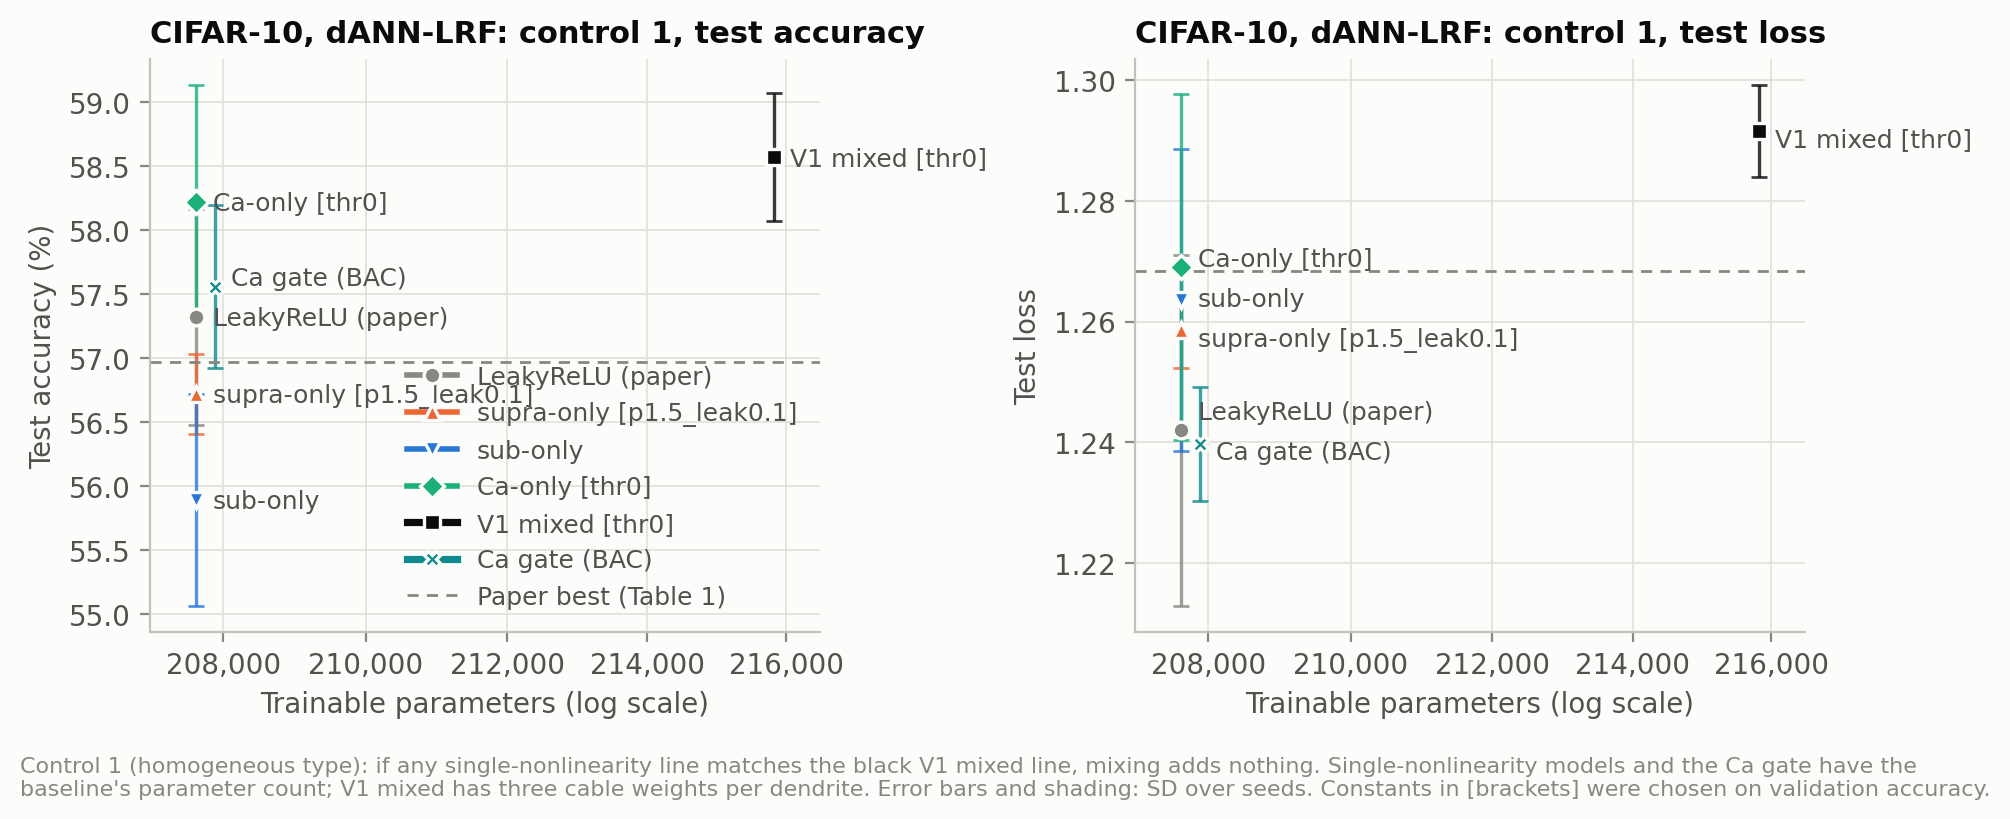

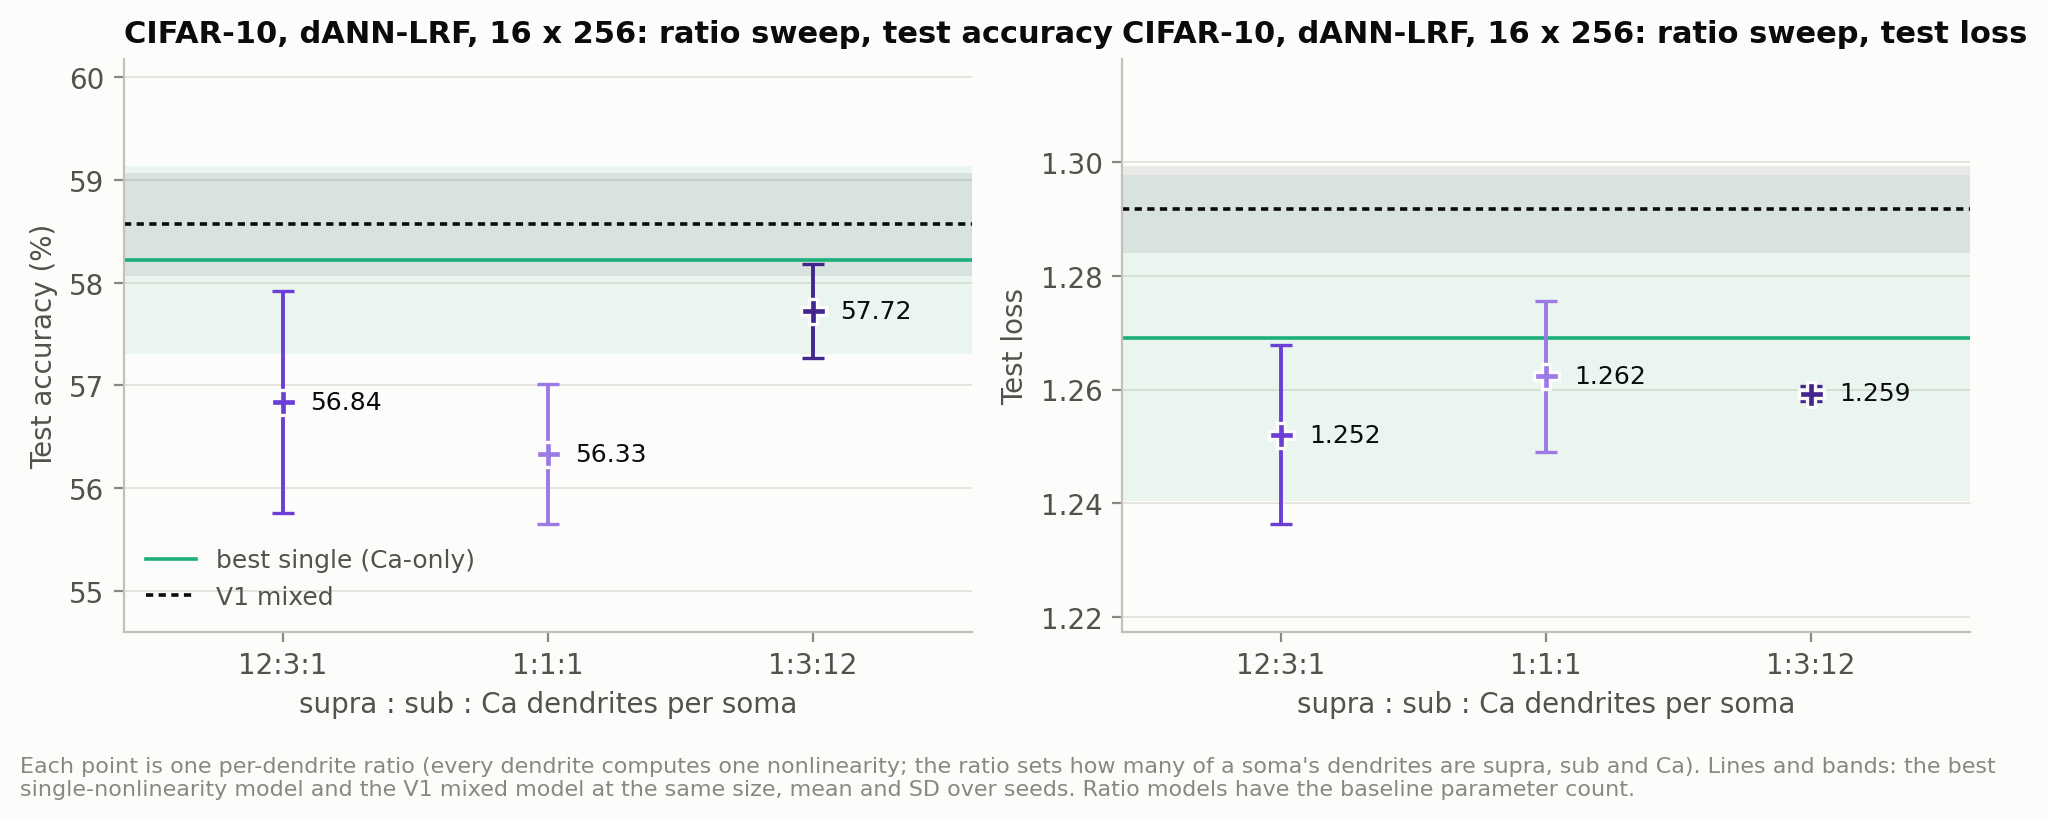

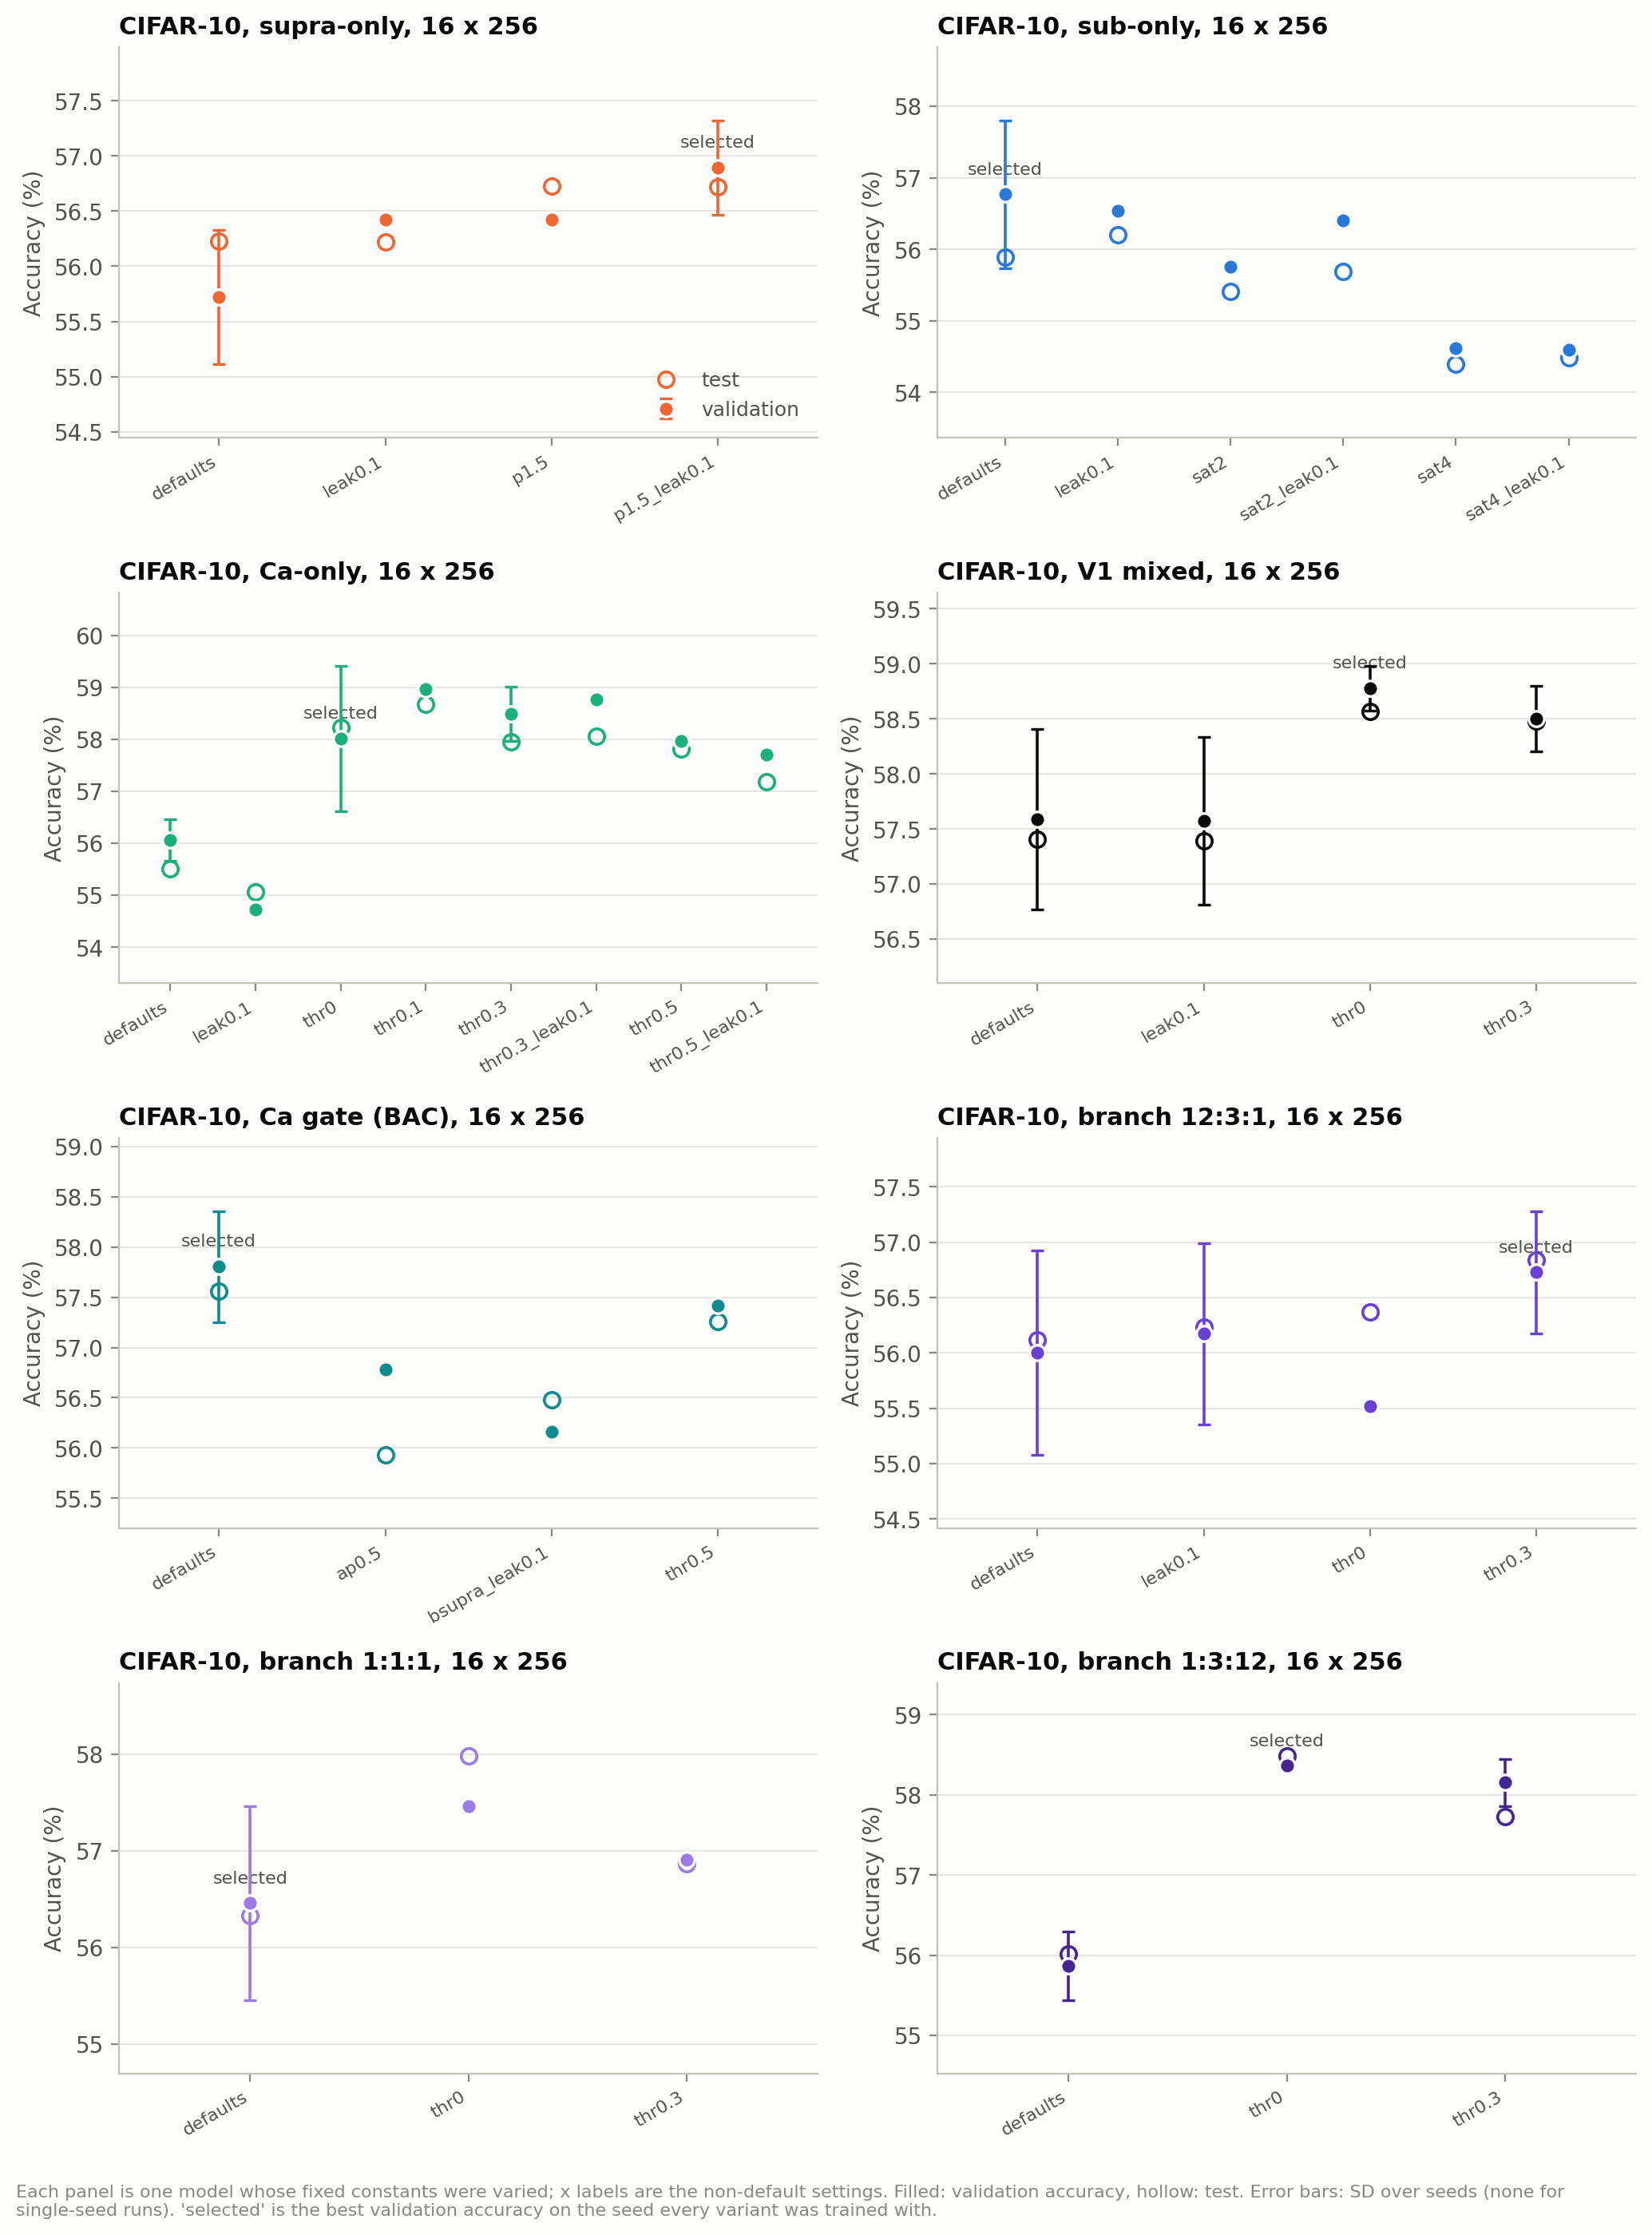

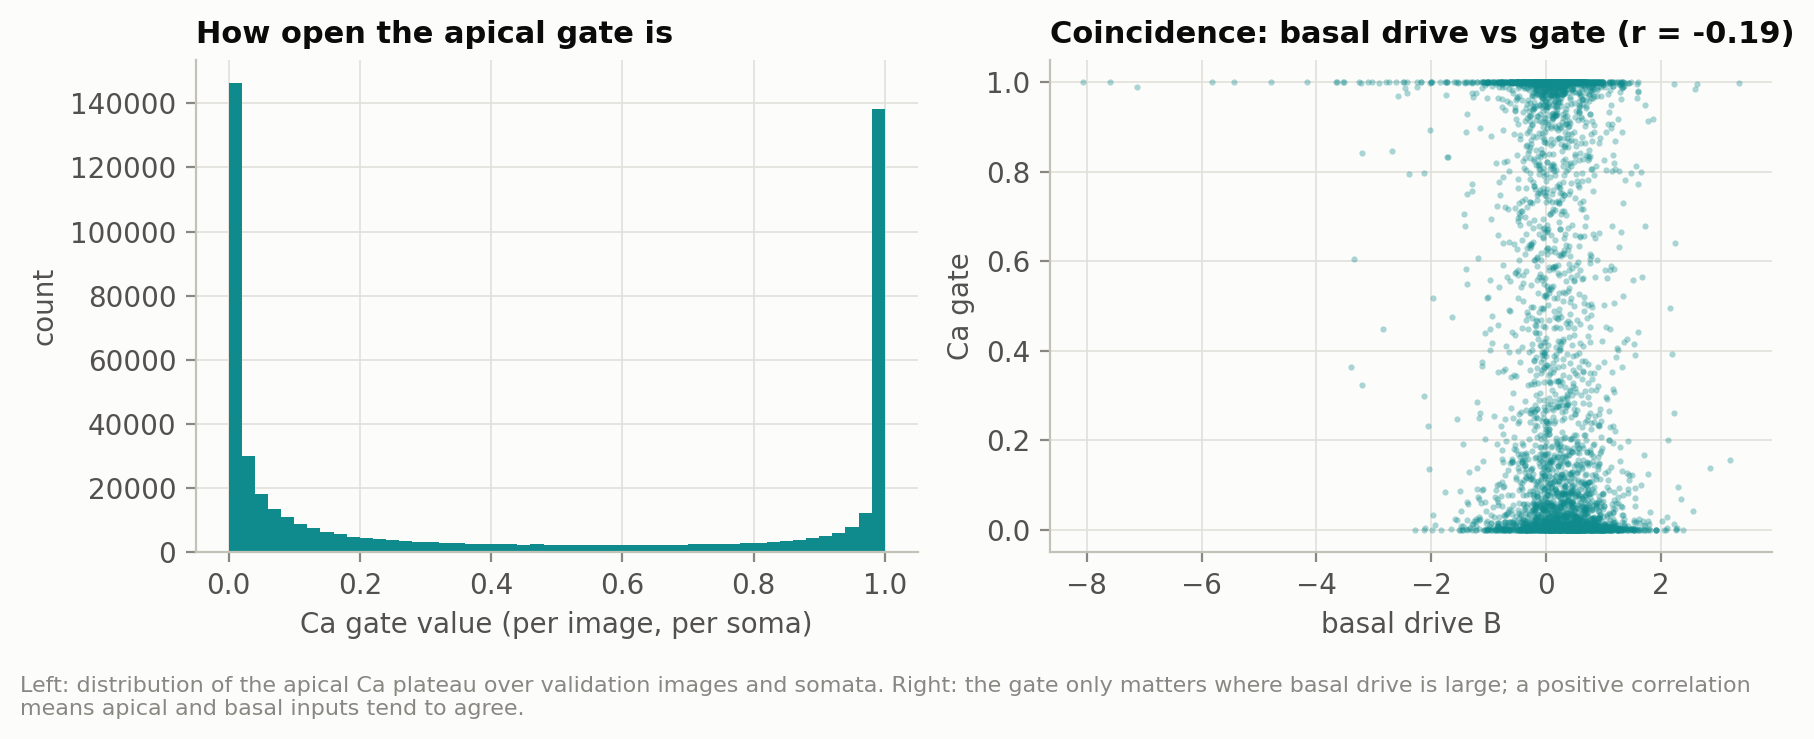

In [14]:
import os
from IPython.display import Image, display
for f in ["7_control_homogeneous.png", "8_ratio_sweep.png", "9_constants_sweep.png", "10_gate_activity.png",
          "11_size_generalisation.png", "12_dendrite_states.png", "13_robustness.png",
          "14_data_efficiency.png", "15_apical_context.png"]:
    if os.path.exists(f"figures/cifar10/{f}"):
        display(Image(f"figures/cifar10/{f}"))

## 7. Bring the results home
Zips the result JSONs (the numbers), the CIFAR-10 figures and the log, and downloads it.
The `.pt` weight files are left out (about 1 MB each); set `INCLUDE_WEIGHTS = True` if you want them.
If the runtime restarted since the sweeps ran, re-run cells 1 and 2 first so `OUT` is defined again.
Locally, unzip into the repo and run `python plot_results.py --results results --dataset cifar10 --out figures/cifar10`
to regenerate the figures from the JSONs.

In [15]:
# Plain Python paths, so this works after a runtime restart (re-run cells 1 and 2 first).
import glob, os, zipfile
INCLUDE_WEIGHTS = False
REPO = "/content/NEU231_Final_Project"
results = sorted(glob.glob(f"{OUT}/*cifar10*" if INCLUDE_WEIGHTS else f"{OUT}/*cifar10*.json"))
assert results, (f"no CIFAR-10 results in {OUT}. Re-run the setup cells (1 and 2); if still empty, "
                 "the VM was recycled and the sweeps must be re-run (use USE_DRIVE = True).")
figs = sorted(glob.glob(f"{REPO}/figures/cifar10/*"))
zip_path = "/content/results_cifar10.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for f in results:
        z.write(f, f"results/{os.path.basename(f)}")
    for f in figs:
        z.write(f, f"figures/cifar10/{os.path.basename(f)}")
    log = f"{REPO}/sweep_controls.log"
    if os.path.exists(log):
        z.write(log, "sweep_controls.log")
print(f"{len(results)} result files, {len(figs)} figures -> {zip_path} "
      f"({os.path.getsize(zip_path) / 1e6:.1f} MB)")
from google.colab import files
files.download(zip_path)

79 result files, 15 figures -> /content/results_cifar10.zip (5.9 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>